# Análisis y optimización de un portafolio de acciones

Este notebook construye, paso a paso, un portafolio con **cualquier cantidad de acciones**.
Cada sección explica *qué* se calcula y *por qué* importa, y luego lo muestra con tablas y gráficas.

**Estructura del proyecto**

| Archivo | Rol |
|---|---|
| `libs.py` | Todas las librerías |
| `acciones.py` | La lógica: datos, métricas, optimización, validación y gráficos |
| `acciones.ipynb` | Este notebook: la parte visual, didáctica e interactiva |

**Ruta:** configuración → datos → rendimientos → métricas por activo → correlación → estimación →
estrategias → frontera eficiente → validación fuera de muestra → portafolio final → laboratorio interactivo.

> Esto es un ejercicio cuantitativo y educativo, no una recomendación de inversión.

In [1]:
# Librerías (todas viven en libs.py) y la lógica del análisis (acciones.py)
from libs import pd, np, plt, widgets, display, Markdown, replace
import acciones as ac

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

Librerias descargadas correctamente


## 1. Configuración

Cambia aquí las acciones y los parámetros y vuelve a ejecutar todo (*Run All*).

| Parámetro | Qué controla |
|---|---|
| `tickers` | Las acciones, tantas como quieras (símbolos de Yahoo Finance) |
| `inicio`, `fin` | Periodo histórico. Más años = estimaciones más estables, pero quizá menos actuales |
| `benchmark` | Índice de referencia para comparar (SPY = S&P 500) |
| `max_peso` | Peso máximo que una acción puede tener en las optimizaciones. Evita concentrarse |
| `mu` | Cómo estimar el rendimiento esperado: `historico`, `ema` (pondera lo reciente) o `capm` (según su beta) |
| `cov` | Cómo estimar el riesgo: `ledoit-wolf` (robusto) o `muestral` |
| `gamma` | Regularización: cuanto más alto, más repartidos los pesos |
| `test` | Fracción final del periodo reservada para validar fuera de muestra |
| `rebalanceo` | Cada cuánto se vuelve a los pesos objetivo |
| `capital` | Dinero a invertir, para calcular cuántas acciones comprar |

In [2]:
cfg = ac.Config(
    tickers=["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "JPM", "KO", "XOM"],
    inicio="2021-01-01",           # fin: por defecto, hoy
    benchmark="SPY",
    max_peso=0.40,
    mu="historico",
    cov="ledoit-wolf",
    gamma=0.1,
    test=0.30,
    rebalanceo="mensual",
    capital=10_000,
)
cfg

Config(tickers=['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA', 'JPM', 'KO', 'XOM'], inicio='2021-01-01', fin='2026-11-10', benchmark='SPY', rf=None, max_peso=0.4, mu='historico', cov='ledoit-wolf', gamma=0.1, test=0.3, rebalanceo='mensual', capital=10000, salida=PosixPath('resultados'), min_cobertura=0.9)

## 2. Descarga y limpieza de datos

Se usan **precios ajustados**: incorporan dividendos y *splits*, así que reflejan el rendimiento total real
(si una acción hace un split 2:1, el precio sin ajustar "cae" 50 % sin que nadie pierda dinero).

La limpieza:
- descarta tickers inválidos o con historial demasiado corto (p. ej. una acción que salió a bolsa hace poco recortaría todo el periodo),
- rellena huecos cortos (feriados distintos entre mercados) y alinea las fechas de todos los activos.

La **tasa libre de riesgo** es lo que ganarías sin riesgo (bonos del Tesoro a 3 meses, `^IRX`). Sirve de vara
para medir si el riesgo de las acciones "valió la pena".

In [3]:
precios, bench = ac.preparar_precios(cfg)
rf = ac.tasa_libre_riesgo(cfg)
print(f"Tasa libre de riesgo promedio del periodo: {rf:.2%}")
precios.tail()

Descargando 8 activos (2021-01-01 → 2026-11-10)...
  Activos válidos: AAPL, AMZN, GOOGL, JPM, KO, MSFT, NVDA, XOM
  Periodo efectivo: 2021-01-04 → 2026-11-09 (1470 días)
Tasa libre de riesgo promedio del periodo: 3.29%


Ticker,AAPL,AMZN,GOOGL,JPM,KO,MSFT,NVDA,XOM
Date,,,,,,,,
2026-11-03,331.899994,250.690002,280.029999,337.980011,94.800003,520.989990,206.690002,177.460007
2026-11-04,349.510010,266.029999,288.929993,352.109985,95.800003,555.799988,200.130005,169.270004
2026-11-05,344.170013,260.209991,282.570007,337.339996,95.730003,535.929993,181.600006,165.300003
2026-11-06,342.369995,259.299988,284.779999,334.489990,95.669998,530.609985,186.639999,165.869995
2026-11-09,350.690002,266.929993,288.149994,342.079987,96.029999,545.179993,178.669998,164.729996


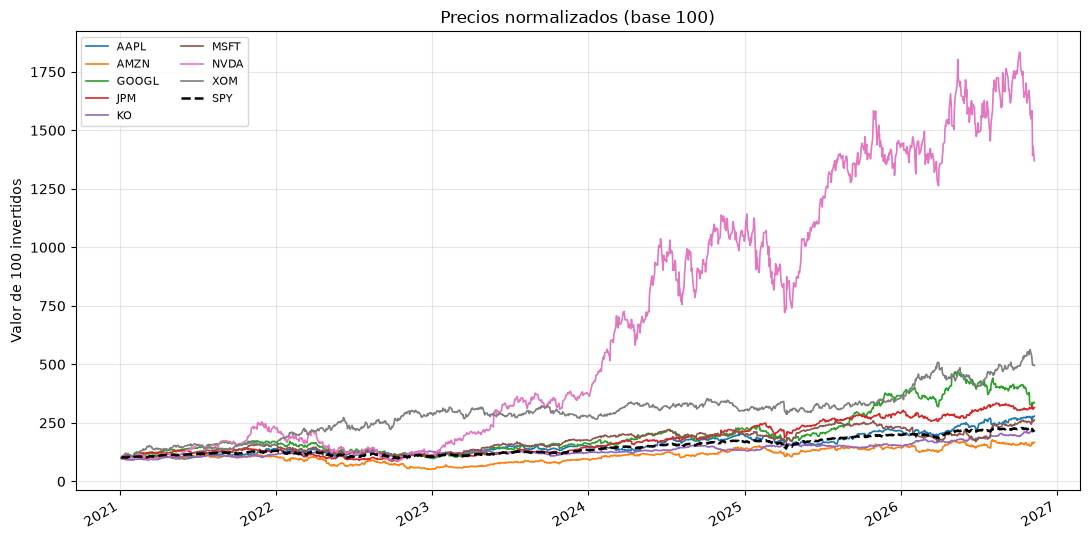

In [4]:
ac.graf_precios(precios, bench);

**Cómo leerla:** todas parten de 100. Si una línea termina en 250, 100 invertidos se convirtieron en 250.
La línea punteada es el benchmark: lo que habrías obtenido comprando el índice completo sin pensar.

## 3. Rendimientos diarios

Los precios no son comparables entre sí (una acción de \$500 no es "mejor" que una de \$50); los **rendimientos** sí:

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

Para anualizar se usa que hay ~252 días hábiles al año: la media se multiplica por 252 y la volatilidad por $\sqrt{252}$
(la varianza crece con el tiempo, la desviación estándar con su raíz).

In [5]:
rend = ac.rendimientos(precios)
bench_rend = ac.rendimientos(bench) if bench is not None else None
rend.describe().T.style.format("{:.4f}")

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,1469.0000,0.0008,0.0174,-0.0925,-0.0080,0.0011,0.0100,0.1533
AMZN,1469.0000,0.0006,0.0221,-0.1405,-0.0114,0.0003,0.0128,0.1532
GOOGL,1469.0000,0.0010,0.0199,-0.1264,-0.0098,0.0014,0.0115,0.1022
JPM,1469.0000,0.0009,0.0152,-0.0748,-0.0071,0.0012,0.0093,0.1154
KO,1469.0000,0.0006,0.0104,-0.0696,-0.0053,0.0007,0.0062,0.0500
MSFT,1469.0000,0.0008,0.0173,-0.0999,-0.0079,0.0007,0.0103,0.1551
NVDA,1469.0000,0.0023,0.0318,-0.1697,-0.0157,0.0025,0.0200,0.2437
XOM,1469.0000,0.0012,0.0171,-0.0789,-0.0089,0.0015,0.0117,0.0641


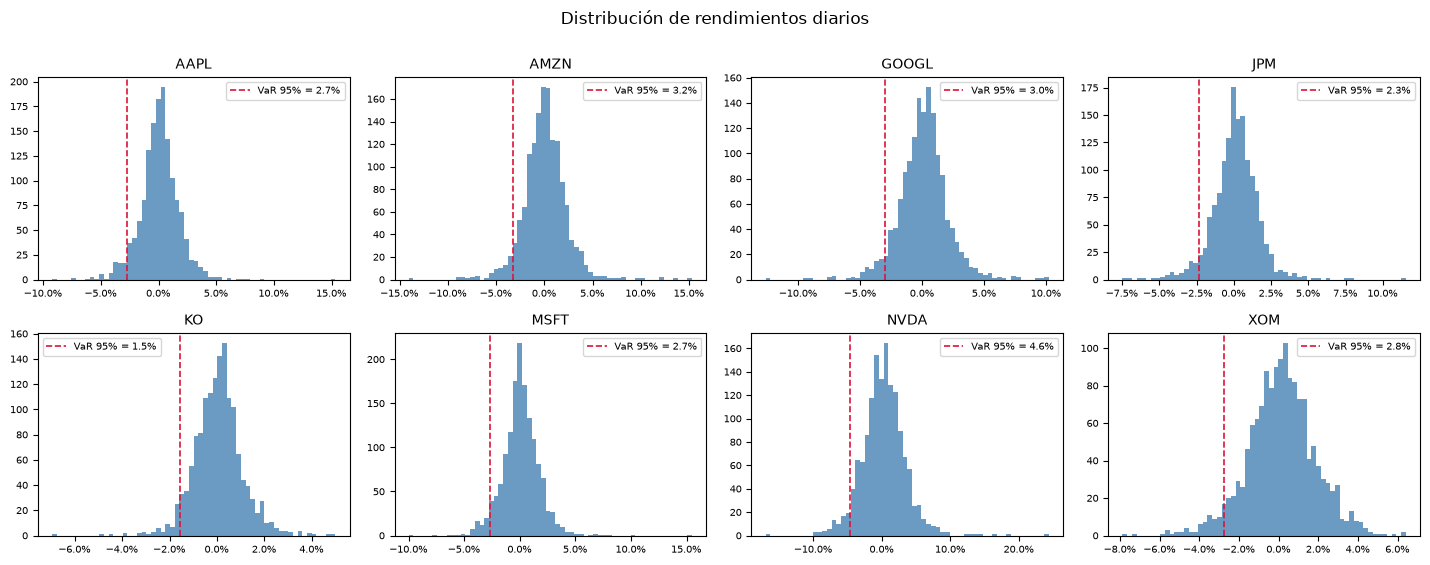

In [6]:
ac.graf_distribucion(rend);

**Cómo leerla:** la mayoría de los días se mueven cerca de 0 %, pero hay colas (días muy malos o muy buenos).
La línea roja es el **VaR 95 %**: en 1 de cada 20 días la pérdida fue *peor* que ese valor.
Colas más largas de lo que predice una campana normal = **curtosis** alta = sorpresas más frecuentes.

## 4. Métricas por activo

| Métrica | Qué mide | Mejor si… |
|---|---|---|
| **CAGR** | Rendimiento anual compuesto realmente obtenido | Alto |
| **Volatilidad** | Desviación estándar anualizada: cuánto "se mueve" | Bajo |
| **Sharpe** | $\frac{R - R_f}{\sigma}$: rendimiento extra por unidad de riesgo | Alto (>1 es muy bueno) |
| **Sortino** | Como Sharpe pero solo penaliza la volatilidad *a la baja* | Alto |
| **Máx. drawdown** | Peor caída desde un máximo hasta un mínimo | Cercano a 0 |
| **Calmar** | CAGR / \|máx. drawdown\| | Alto |
| **VaR / CVaR 95 %** | Pérdida diaria en el peor 5 % de días / promedio de ese peor 5 % | Bajo |
| **Asimetría** | Negativa = caídas grandes más frecuentes que subidas grandes | ≥ 0 |
| **Curtosis** | Colas gruesas (eventos extremos) | Bajo |
| **Beta** | Sensibilidad al mercado: beta 1.5 → si el mercado cae 10 %, tiende a caer 15 % | Depende |
| **Alfa** | Rendimiento que *no* explica el mercado (según CAPM) | Alto |
| **Information ratio** | Rendimiento extra vs. benchmark / variabilidad de esa diferencia | Alto |

In [7]:
tabla = rend.copy()
if bench_rend is not None:
    tabla[f"[{bench.name}]"] = bench_rend
met_activos = ac.tabla_metricas(tabla, rf, bench_rend)
ac.estilo(met_activos)

,Rend. total,Rend. anual (CAGR),Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% diario,CVaR 95% diario,Asimetría,Curtosis,% días positivos,Beta,Alfa anual,Tracking error,Information ratio
AAPL,179.14%,19.26%,27.64%,0.66,0.97,-33.36%,0.58,2.70%,3.89%,0.35,6.09,52.96%,1.17,4.48%,19.75%,0.33
AMZN,67.53%,9.26%,35.14%,0.33,0.49,-56.15%,0.16,3.23%,4.84%,0.35,5.82,51.19%,1.45,-5.26%,26.53%,0.00
GOOGL,237.05%,23.17%,31.59%,0.72,1.05,-44.32%,0.52,2.99%,4.40%,-0.00,4.02,53.23%,1.25,7.95%,24.07%,0.45
JPM,215.40%,21.78%,24.05%,0.81,1.17,-38.77%,0.56,2.34%,3.48%,0.09,4.67,54.05%,0.87,9.15%,19.26%,0.40
KO,115.67%,14.09%,16.46%,0.69,1.01,-17.27%,0.82,1.55%,2.20%,-0.06,3.24,52.89%,0.26,8.28%,20.13%,-0.02
MSFT,162.65%,18.02%,27.41%,0.62,0.93,-37.15%,0.48,2.67%,3.67%,0.55,7.02,51.94%,1.13,3.79%,19.95%,0.27
NVDA,1269.52%,56.67%,50.52%,1.08,1.66,-66.34%,0.85,4.63%,6.55%,0.49,4.53,53.10%,2.10,29.78%,40.78%,1.05
XOM,395.41%,31.59%,27.22%,1.03,1.50,-20.51%,1.54,2.75%,3.78%,-0.18,1.07,53.85%,0.42,23.06%,28.06%,0.58
[SPY],120.35%,14.51%,16.69%,0.70,1.01,-24.50%,0.59,1.62%,2.42%,0.23,8.88,54.25%,1.00,0.00%,0.00%,-


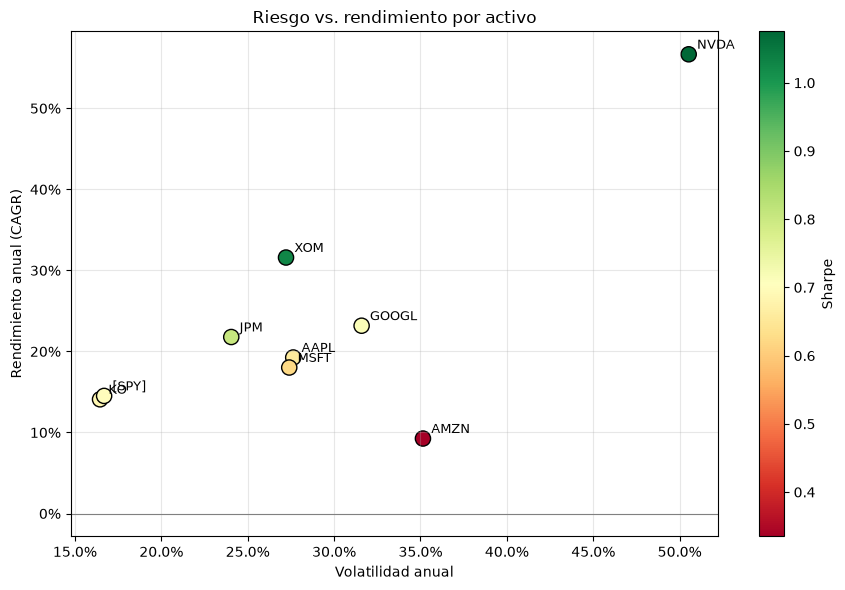

In [8]:
ac.graf_riesgo_rendimiento(met_activos);

**Cómo leerla:** arriba a la izquierda es el lugar ideal (mucho rendimiento, poco riesgo).
Dos acciones con el mismo rendimiento no son iguales si una lo logra con el doble de volatilidad.

## 5. Correlación: la clave de la diversificación

La volatilidad de un portafolio **no** es el promedio de las volatilidades:

$$\sigma_p^2 = \sum_i \sum_j w_i w_j \sigma_i \sigma_j \rho_{ij}$$

Si dos activos tienen correlación $\rho$ baja, cuando uno cae el otro no necesariamente lo hace, y el portafolio
oscila menos que cada uno por separado. Es "el único almuerzo gratis" de las finanzas.

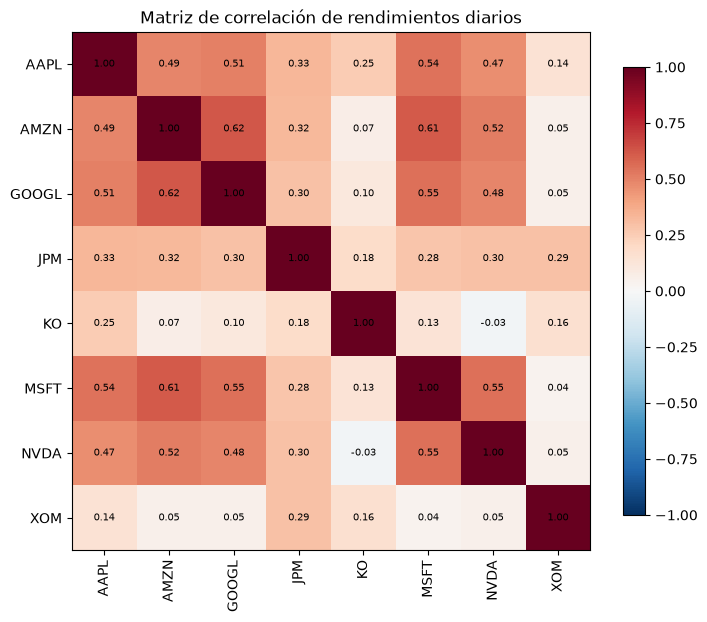

In [9]:
corr = rend.corr()
ac.graf_correlacion(corr);

In [10]:
if len(corr) > 1:
    altos, bajos = ac.pares_correlacion(corr)
    prom = corr.values[np.triu_indices(len(corr), 1)].mean()
    display(Markdown(f"**Correlación promedio:** {prom:.2f}"))
    display(pd.concat({"Más correlacionados (diversifican poco)": altos.reset_index(drop=False),
                       "Menos correlacionados (diversifican más)": bajos.reset_index(drop=False)}, axis=1)
              .style.format(precision=2).hide(axis="index"))

**Correlación promedio:** 0.30

## 6. Estimar el futuro: rendimiento esperado (μ) y covarianza (Σ)

Optimizar requiere dos insumos: cuánto esperamos que rinda cada acción (**μ**) y cómo se mueven juntas (**Σ**).
Ambos se estiman con el pasado, y **ahí está el punto débil de toda la teoría**:

- **μ es muy ruidoso.** Con 5 años de datos el error de estimación del rendimiento anual de una acción es de ±10–15 puntos.
  El optimizador "se enamora" de quien tuvo suerte en el pasado.
- **Σ es más estable**, pero con muchos activos la matriz muestral es poco fiable. **Ledoit-Wolf** la "encoge" hacia
  una estructura más simple, lo que reduce errores extremos.

Por eso el análisis usa límites de peso, regularización y, sobre todo, **validación fuera de muestra** (sección 9).

In [11]:
mu, S = ac.estimar_mu_S(precios, bench, cfg, rf)
_, S_muestral = ac.estimar_mu_S(precios, bench, replace(cfg, cov="muestral"), rf)

comparacion = pd.DataFrame({
    "μ esperado": mu,
    "Volatilidad (Ledoit-Wolf)": np.sqrt(np.diag(S)),
    "Volatilidad (muestral)": np.sqrt(np.diag(S_muestral)),
})
display(comparacion.style.format("{:.2%}"))
print(f"Número de condición de Σ  →  muestral: {np.linalg.cond(S_muestral):,.0f}   "
      f"Ledoit-Wolf: {np.linalg.cond(S):,.0f}   (más bajo = más estable al invertirla)")

,μ esperado,Volatilidad (Ledoit-Wolf),Volatilidad (muestral)
Ticker,,,
AAPL,19.26%,27.67%,27.64%
AMZN,9.26%,35.09%,35.14%
GOOGL,23.17%,31.58%,31.59%
JPM,21.78%,24.14%,24.05%
KO,14.09%,16.69%,16.46%
MSFT,18.02%,27.44%,27.41%
NVDA,56.67%,50.34%,50.52%
XOM,31.59%,27.26%,27.22%


Número de condición de Σ  →  muestral: 19   Ledoit-Wolf: 18   (más bajo = más estable al invertirla)


## 7. Siete estrategias para construir el portafolio

| Estrategia | Idea | Usa μ | Usa Σ |
|---|---|:-:|:-:|
| **Igual peso** | $1/N$ a cada acción. Simple y sorprendentemente difícil de superar | No | No |
| **Inversa volatilidad** | Más peso a las acciones menos volátiles | No | Solo diagonal |
| **Paridad de riesgo** | Cada acción aporta **el mismo riesgo** (no el mismo dinero) | No | Sí |
| **Mínima volatilidad** | El portafolio menos volátil posible | No | Sí |
| **Máximo Sharpe** | El de mejor rendimiento por unidad de riesgo (Markowitz clásico) | Sí | Sí |
| **Mínimo CVaR** | Minimiza la pérdida promedio en los peores días | Sí | (escenarios) |
| **HRP** | Agrupa acciones parecidas en un árbol y reparte riesgo entre grupos (López de Prado) | No | Sí |

Las que **no usan μ** son más robustas porque evitan el insumo más ruidoso.

In [12]:
pesos = ac.construir_portafolios(precios, bench, cfg, rf)
ac.estilo_pesos(pd.DataFrame(pesos))

,Igual peso,Inversa volatilidad,Paridad de riesgo,Mínima volatilidad,Máximo Sharpe,Mínimo CVaR,HRP
Ticker,,,,,,,
AAPL,12.5%,12.4%,9.9%,10.3%,2.7%,-,11.7%
AMZN,12.5%,9.8%,8.2%,6.2%,-,-,4.7%
GOOGL,12.5%,10.9%,9.2%,9.1%,7.3%,-,5.9%
JPM,12.5%,14.3%,13.4%,16.0%,13.0%,18.3%,15.3%
KO,12.5%,20.6%,26.3%,26.7%,15.9%,40.0%,37.3%
MSFT,12.5%,12.5%,10.4%,12.1%,0.9%,21.7%,8.5%
NVDA,12.5%,6.8%,6.3%,1.3%,28.7%,-,2.5%
XOM,12.5%,12.6%,16.3%,18.4%,31.6%,19.9%,14.0%


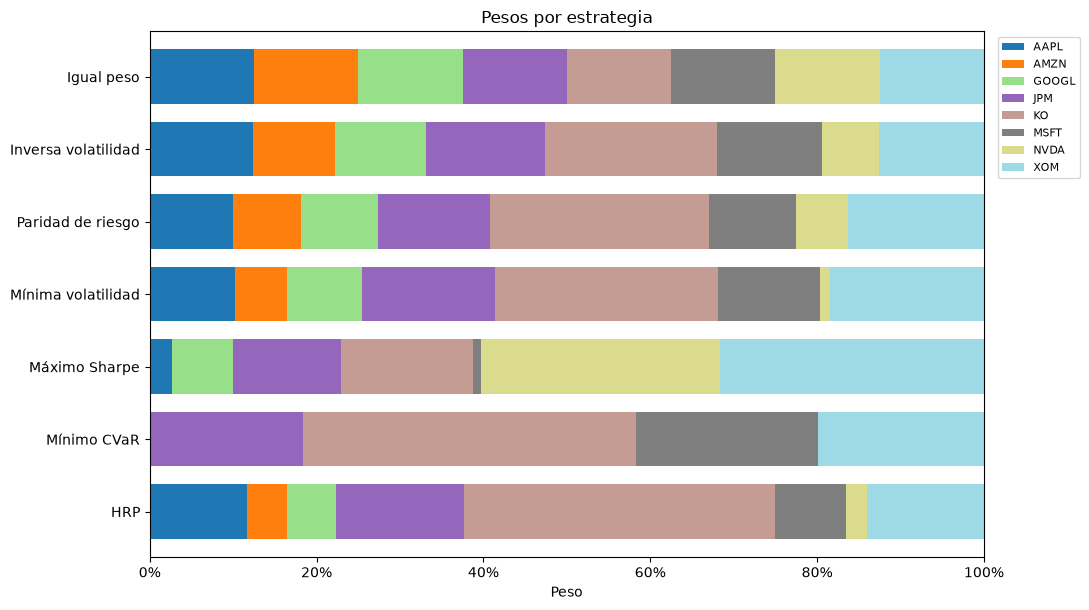

In [13]:
ac.graf_pesos(pesos);

In [14]:
ex_ante = ac.desempeño_ex_ante(pesos, mu, S, rf)
ac.estilo(ex_ante, colorear=("Sharpe", "Activos efectivos"))

,Rend. esperado,Volatilidad esperada,Sharpe,N° activos,Activos efectivos
Igual peso,24.23%,19.50%,1.07,8.00,8.00
Inversa volatilidad,21.96%,17.02%,1.10,8.00,7.35
Paridad de riesgo,22.00%,15.78%,1.19,8.00,6.51
Mínima volatilidad,20.62%,14.95%,1.16,8.00,5.94
Máximo Sharpe,33.66%,20.71%,1.47,7.00,4.34
Mínimo CVaR,19.84%,13.84%,1.20,4.00,3.56
HRP,20.04%,14.30%,1.17,8.00,4.77


**Activos efectivos** $= 1/\sum w_i^2$: con 8 acciones a igual peso vale 8; si casi todo está en una sola, se acerca a 1.
Mide qué tan diversificado está *realmente* el portafolio.

## 8. Frontera eficiente

Cada punto de color es un portafolio aleatorio. La **línea negra** es la frontera eficiente: para cada nivel de riesgo,
el máximo rendimiento esperado posible. Ningún portafolio puede estar por encima de ella (según las estimaciones).

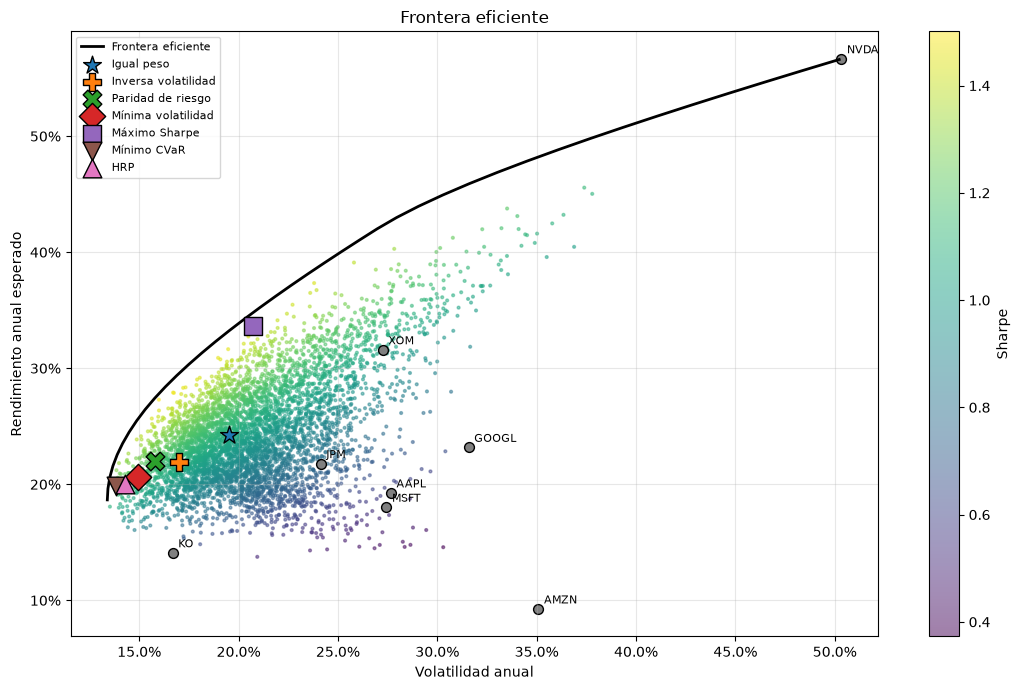

In [15]:
ac.graf_frontera(mu, S, pesos, rf);

**Ojo:** esta gráfica usa las estimaciones de todo el historial, así que el "Máximo Sharpe" siempre se ve
espectacular *aquí*. La pregunta real es si eso se mantiene en datos que el modelo no vio.

## 9. Validación fuera de muestra (la prueba de fuego)

1. Se toma el primer **70 %** del periodo (*entrenamiento*) y con él se calculan los pesos de cada estrategia.
2. Se "congela" ese portafolio y se mide qué pasó en el **30 %** restante (*prueba*), rebalanceando periódicamente.

Así se simula lo que habría vivido un inversionista real: decidir con la información disponible y luego esperar.
Si una estrategia brilla dentro de muestra pero no fuera, estaba **sobreajustada** (*overfitting*).

In [16]:
oos = ac.validar_fuera_de_muestra(precios, bench, cfg, rf)
if oos is not None:
    display(Markdown(f"**Entrenamiento:** {oos.periodo_train[0]} → {oos.periodo_train[1]} &nbsp;&nbsp; "
                     f"**Prueba:** {oos.periodo_test[0]} → {oos.periodo_test[1]}"))
    display(ac.estilo(oos.metricas))

**Entrenamiento:** 2021-01-04 → 2025-02-06 &nbsp;&nbsp; **Prueba:** 2025-02-07 → 2026-11-09

,Rend. total,Rend. anual (CAGR),Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% diario,CVaR 95% diario,Asimetría,Curtosis,% días positivos,Beta,Alfa anual,Tracking error,Information ratio
HRP,53.77%,27.87%,12.58%,1.76,2.78,-11.97%,2.33,0.95%,1.53%,0.43,13.04,55.56%,0.47,16.68%,13.36%,0.78
Mínimo CVaR,53.02%,27.52%,12.76%,1.72,2.68,-9.45%,2.91,1.07%,1.57%,0.08,8.95,56.92%,0.36,17.62%,15.63%,0.65
Mínima volatilidad,52.38%,27.21%,13.39%,1.62,2.52,-14.18%,1.92,1.12%,1.75%,0.54,16.07,54.65%,0.57,15.05%,11.69%,0.86
Paridad de riesgo,51.93%,27.00%,13.87%,1.56,2.40,-15.43%,1.75,1.16%,1.87%,0.78,19.28,54.65%,0.66,13.93%,9.89%,1.00
Inversa volatilidad,50.20%,26.17%,14.98%,1.41,2.17,-16.86%,1.55,1.29%,2.03%,0.96,18.74,55.10%,0.74,12.42%,8.83%,1.07
Igual peso,48.37%,25.29%,17.24%,1.21,1.83,-19.26%,1.31,1.46%,2.39%,1.00,18.44,56.01%,0.89,10.31%,7.71%,1.18
Máximo Sharpe,52.28%,27.16%,21.62%,1.07,1.58,-20.18%,1.35,1.83%,3.02%,0.38,12.46,55.33%,0.94,12.13%,14.26%,0.80
[SPY],26.58%,14.42%,17.37%,0.68,0.99,-18.76%,0.77,1.57%,2.45%,1.10,21.90,54.20%,1.00,0.00%,0.00%,-


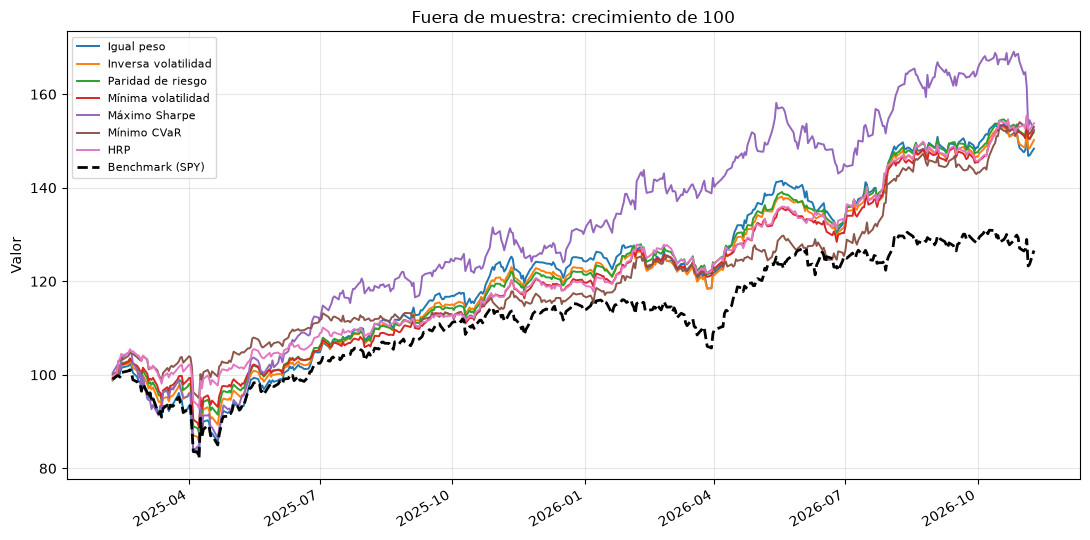

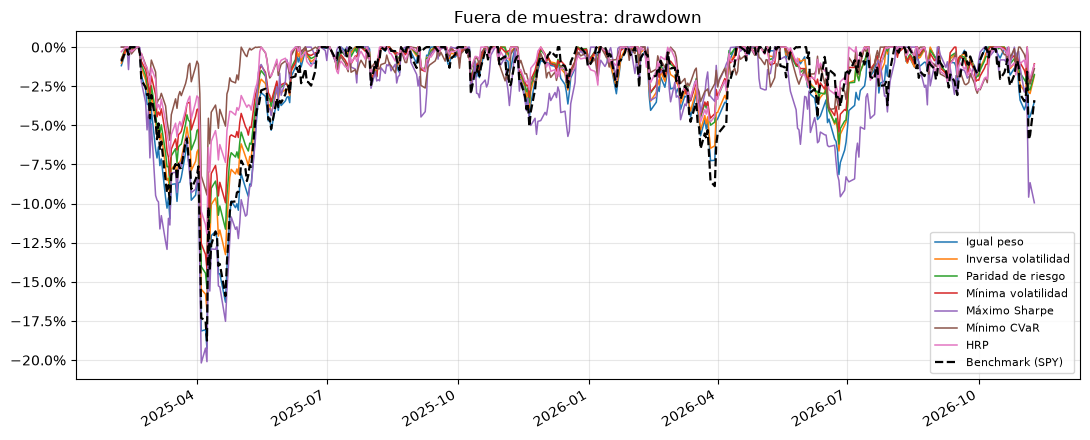

In [17]:
if oos is not None:
    ac.graf_crecimiento(oos.rendimientos, oos.benchmark, "Fuera de muestra: crecimiento de 100");
    ac.graf_drawdown(oos.rendimientos, oos.benchmark, "Fuera de muestra: drawdown");

**Cómo leerlas:** la primera muestra cuánto habrías ganado; la segunda cuánto habrías sufrido en el camino.
Una estrategia con algo menos de ganancia pero caídas mucho menores suele ser más fácil de sostener en la vida real.

**¿Y dentro de muestra?** Comparar con la tabla de arriba muestra el sesgo: las optimizaciones siempre lucen mejor
con los datos con los que fueron entrenadas.

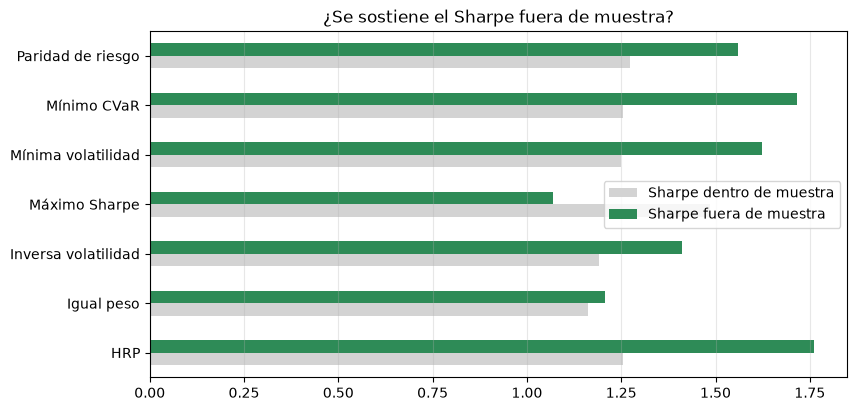

In [18]:
met_hist = ac.tabla_metricas(ac.simular_todos(rend, pesos, cfg.rebalanceo), rf, bench_rend)
cols = ["Rend. anual (CAGR)", "Volatilidad", "Sharpe", "Máx. drawdown"]
if oos is not None:
    sharpe = pd.DataFrame({"Sharpe dentro de muestra": met_hist["Sharpe"],
                           "Sharpe fuera de muestra": oos.metricas["Sharpe"]}).dropna()
    ax = sharpe.plot.barh(figsize=(9, 4.5), color=["lightgray", "seagreen"])
    ax.set_title("¿Se sostiene el Sharpe fuera de muestra?"); ax.grid(alpha=0.3, axis="x")

## 10. Portafolio final

Se sugiere la estrategia con **mejor Sharpe fuera de muestra**, y sus pesos se recalculan con **todo** el historial
(la información más completa disponible hoy).

La gráfica compara el **dinero** invertido en cada acción con el **riesgo** que aporta. Una acción con 10 % del capital
puede aportar 25 % del riesgo si es muy volátil o está muy correlacionada con las demás.

### Portafolio sugerido: **HRP**  
*Criterio: mejor Sharpe fuera de muestra*

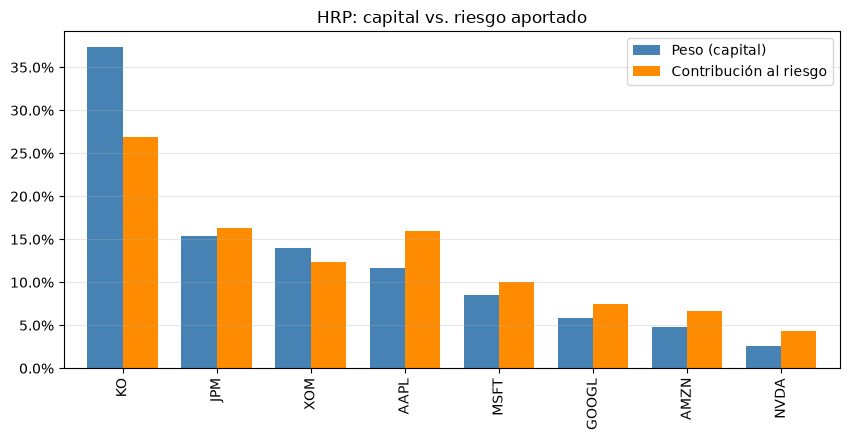

In [19]:
elegido, motivo = ac.elegir_sugerido(pesos, oos, ex_ante)
w = pesos[elegido]
display(Markdown(f"### Portafolio sugerido: **{elegido}**  \n*Criterio: {motivo}*"))
ac.graf_contribucion(w, S, f"{elegido}: capital vs. riesgo aportado");

In [20]:
if cfg.capital:
    compra, sobrante = ac.asignacion_discreta(w, precios, cfg.capital)
    display(Markdown(f"**Compra con ${cfg.capital:,.0f}** (precios del {precios.index[-1].date()}) — "
                     f"efectivo sobrante: **${sobrante:,.2f}**"))
    display(compra.style.format({"Precio": "${:,.2f}", "Monto": "${:,.2f}",
                                 "Peso real": "{:.1%}", "Peso objetivo": "{:.1%}"}))

**Compra con $10,000** (precios del 2026-11-09) — efectivo sobrante: **$54.77**

,Acciones,Precio,Monto,Peso real,Peso objetivo
KO,38,$96.03,"$3,649.14",36.5%,37.3%
JPM,4,$342.08,"$1,368.32",13.7%,15.3%
XOM,8,$164.73,"$1,317.84",13.2%,14.0%
MSFT,2,$545.18,"$1,090.36",10.9%,8.5%
AAPL,3,$350.69,"$1,052.07",10.5%,11.7%
GOOGL,2,$288.15,$576.30,5.8%,5.9%
AMZN,2,$266.93,$533.86,5.3%,4.7%
NVDA,2,$178.67,$357.34,3.6%,2.5%


## 11. Laboratorio interactivo

Mueve los controles y observa cómo cambia el portafolio **sin volver a descargar datos**.
Preguntas para explorar:

- ¿Qué pasa con "Máximo Sharpe" si subes `max_peso` a 100 % y `gamma` a 0? (pista: se concentra)
- ¿Cambian mucho los pesos al pasar `mu` de `historico` a `capm`? Eso muestra cuán frágil es estimar rendimientos.
- ¿La paridad de riesgo cambia con `mu`? ¿Por qué no?

> Los controles requieren un kernel activo (Jupyter / VS Code). Si solo ves el texto, ejecuta la celda.

In [21]:
estrategias = list(pesos)

def laboratorio(estrategia, max_peso, gamma, mu_metodo, cov_metodo):
    c = replace(cfg, max_peso=max_peso, gamma=gamma, mu=mu_metodo, cov=cov_metodo)
    p = ac.construir_portafolios(precios, bench, c, rf)
    if estrategia not in p:
        print(f"'{estrategia}' no se pudo calcular con estos parámetros."); return
    m, s = ac.estimar_mu_S(precios, bench, c, rf)
    display(ac.estilo(ac.desempeño_ex_ante({estrategia: p[estrategia]}, m, s, rf), colorear=()))
    ac.graf_contribucion(p[estrategia], s, f"{estrategia}: capital vs. riesgo"); plt.show()
    ac.graf_frontera(m, s, p, rf, destacar=estrategia, n_aleatorios=2000); plt.show()

widgets.interact(
    laboratorio,
    estrategia=widgets.Dropdown(options=estrategias, value="Máximo Sharpe" if "Máximo Sharpe" in estrategias else estrategias[0], description="Estrategia"),
    max_peso=widgets.FloatSlider(value=cfg.max_peso, min=0.10, max=1.0, step=0.05, description="Peso máx.",
                                 readout_format=".0%", continuous_update=False),
    gamma=widgets.FloatSlider(value=cfg.gamma, min=0, max=2, step=0.05, description="Gamma L2",
                              continuous_update=False),
    mu_metodo=widgets.ToggleButtons(options=["historico", "ema", "capm"], value=cfg.mu, description="μ"),
    cov_metodo=widgets.ToggleButtons(options=["ledoit-wolf", "muestral"], value=cfg.cov, description="Σ"),
);

interactive(children=(Dropdown(description='Estrategia', index=4, options=('Igual peso', 'Inversa volatilidad'…

### Laboratorio 2: validación fuera de muestra

¿Cambia la estrategia ganadora si cambias el tamaño del periodo de prueba o la frecuencia de rebalanceo?
Si el ranking cambia mucho, ninguna estrategia es claramente superior: la diferencia era suerte.

In [22]:
def laboratorio_oos(test, rebalanceo):
    c = replace(cfg, test=test, rebalanceo=rebalanceo)
    o = ac.validar_fuera_de_muestra(precios, bench, c, rf)
    if o is None:
        return
    display(Markdown(f"**Entrenamiento:** {o.periodo_train[0]} → {o.periodo_train[1]} &nbsp;&nbsp; "
                     f"**Prueba:** {o.periodo_test[0]} → {o.periodo_test[1]}"))
    display(ac.estilo(o.metricas[["Rend. anual (CAGR)", "Volatilidad", "Sharpe", "Máx. drawdown"]]))
    ac.graf_crecimiento(o.rendimientos, o.benchmark, "Fuera de muestra: crecimiento de 100"); plt.show()

widgets.interact(
    laboratorio_oos,
    test=widgets.FloatSlider(value=cfg.test, min=0.10, max=0.60, step=0.05, description="% prueba",
                             readout_format=".0%", continuous_update=False),
    rebalanceo=widgets.Dropdown(options=list(ac.REBALANCEOS), value=cfg.rebalanceo, description="Rebalanceo"),
);

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='% prueba', max=0.6, min=0.1…

## 12. Conclusiones y limitaciones

- **El pasado no se repite tal cual.** Todo se estima con historia; un periodo distinto puede dar pesos muy distintos.
- **Estimar rendimientos es lo más difícil.** Por eso las estrategias que solo usan riesgo (paridad de riesgo, HRP,
  mínima volatilidad) suelen sostenerse mejor fuera de muestra que "Máximo Sharpe".
- **Faltan costos reales:** comisiones, impuestos y *spread* al rebalancear no están incluidos.
- **Sesgo de supervivencia:** elegir acciones que hoy conocemos (porque les fue bien) infla los resultados históricos.
- **Diversificación sectorial:** si todas las acciones son del mismo sector, la correlación alta limita cuánto se puede reducir el riesgo.

Para un reporte rápido sin notebook:
```bash
python acciones.py AAPL MSFT KO XOM --capital 10000
```